# Tutorial 11: Semantic Segmentation using a Pretrained Model (DeepLabV3) and Mask R-CNN in PyTorch

## Block 1: Import libraries

In [4]:
import json
import time
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
import yaml
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision import models, transforms
from torchvision.models.segmentation import (deeplabv3_resnet101, DeepLabV3_ResNet101_Weights,
                                             deeplabv3_resnet50, DeepLabV3_ResNet50_Weights)
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from google.colab import files

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
print('Device:', device)

Device: cuda


## Block 2: Load pretrained model

In [5]:
# Load DeepLabV3 with a ResNet-101 backbone, pretrained on COCO images labelled with the 20 Pascal VOC classes
# (weights= replaces the older pretrained=True argument)
weights = DeepLabV3_ResNet101_Weights.DEFAULT
model = deeplabv3_resnet101(weights=weights).to(device)
model.eval()  # Set model to evaluation mode

VOC_CLASSES = weights.meta['categories']
print(len(VOC_CLASSES), 'classes:', VOC_CLASSES)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet101_coco-586e9e4e.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet101_coco-586e9e4e.pth


100%|██████████| 233M/233M [00:02<00:00, 122MB/s]


21 classes: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
Parameters: 60,996,202


## Block 3: Load and preprocess a random image

In [6]:
# Load a random image: upload any photo, ideally with people, animals, vehicles or furniture
uploaded = files.upload()
image_path = list(uploaded.keys())[0]
image = ImageOps.exif_transpose(Image.open(image_path)).convert('RGB')
image.thumbnail((1024, 1024))  # large phone photos are reduced to at most 1024 pixels

# Define preprocessing pipeline
preprocess = transforms.Compose([
    transforms.ToTensor(),  # Convert image to Tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize as required by the model
])

# Preprocess the image
input_tensor = preprocess(image).unsqueeze(0).to(device)  # Add batch dimension
print('Image size:', image.size, '| Input tensor:', tuple(input_tensor.shape))

Saving random-shot-of-california-street-intersection.webp to random-shot-of-california-street-intersection.webp
Image size: (1024, 683) | Input tensor: (1, 3, 683, 1024)


## Block 4: Perform segmentation

In [7]:
# Perform inference
with torch.no_grad():
    output = model(input_tensor)['out'][0]  # Extract segmentation output

# Convert output to class predictions
output_predictions = output.argmax(0).cpu()  # Take the class with the highest probability
print('Output scores:', tuple(output.shape), '-> one score per class for every pixel')
print('Predictions:', tuple(output_predictions.shape))

Output scores: (21, 683, 1024) -> one score per class for every pixel
Predictions: (683, 1024)


## Block 5: Visualize the segmentation results

Classes found:
  __background__  93.3% of the pixels
  car              6.0% of the pixels
  motorbike        0.4% of the pixels
  person           0.2% of the pixels


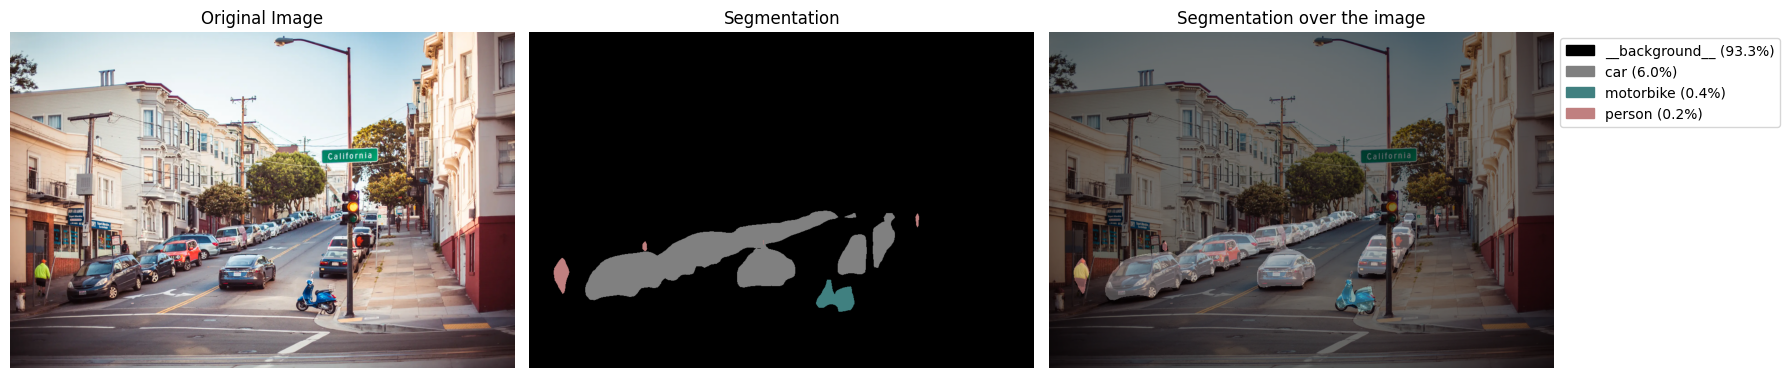

In [8]:
# Color palette for Pascal VOC (21 classes)
VOC_COLORS = np.array([
    [0, 0, 0], [128, 0, 0], [0, 128, 0], [128, 128, 0],
    [0, 0, 128], [128, 0, 128], [0, 128, 128], [128, 128, 128],
    [64, 0, 0], [192, 0, 0], [64, 128, 0], [192, 128, 0],
    [64, 0, 128], [192, 0, 128], [64, 128, 128], [192, 128, 128],
    [0, 64, 0], [128, 64, 0], [0, 192, 0], [128, 192, 0],
    [0, 64, 128]
])


# Map class predictions to colors
def decode_segmentation(mask, num_classes=21):
    colors = VOC_COLORS
    r = np.zeros_like(mask, dtype=np.uint8)
    g = np.zeros_like(mask, dtype=np.uint8)
    b = np.zeros_like(mask, dtype=np.uint8)
    for cls in range(num_classes):
        idx = mask == cls
        r[idx] = colors[cls, 0]
        g[idx] = colors[cls, 1]
        b[idx] = colors[cls, 2]
    return np.stack([r, g, b], axis=2)


def class_legend(mask, names, colors):
    values, counts = np.unique(mask, return_counts=True)
    handles = [patches.Patch(color=colors[v] / 255, label=f'{names[v]} ({c / mask.size * 100:.1f}%)')
               for v, c in zip(values, counts)]
    return handles


# Decode the segmentation map
pred = output_predictions.numpy()
segmentation_map = decode_segmentation(pred)

print('Classes found:')
for v, c in zip(*np.unique(pred, return_counts=True)):
    print(f'  {VOC_CLASSES[v]:14} {c / pred.size * 100:5.1f}% of the pixels')

# Plot the original image and the segmentation
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Segmentation")
plt.imshow(segmentation_map)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Segmentation over the image")
plt.imshow(image)
plt.imshow(segmentation_map, alpha=0.55)
plt.axis('off')
plt.legend(handles=class_legend(pred, VOC_CLASSES, VOC_COLORS), loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## Block 6: Task 1 - Read the boxes drawn on the images

In [9]:
# Reads the boxes back from images that have labelled boxes drawn on them
# (e.g. Annotated_Images.zip): every class was drawn in its own exact colour with a name tag,
# so each tag is found by exact template matching and its rectangle is traced from the line pixels.
# The drawings are then painted out (inpainting) so the detectors are tested on clean pictures.
# Colours used when the boxes were drawn (RGB), one per class
CLASS_COLORS = {
    'trafficlight': (255, 193, 7),
    'stop': (220, 53, 69),
    'speedlimit': (0, 123, 255),
    'crosswalk': (40, 167, 69),
}


def draw_style(shape):
    h, w = shape[:2]
    return max(2, round(min(h, w) / 150)), max(0.4, min(h, w) / 600)


def tag_size(name, shape):
    _, fs = draw_style(shape)
    (tw, th), base = cv2.getTextSize(name, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
    return tw, th, base


def draw_box(canvas, name, x1, y1, x2, y2, color, outline=True, tag=True):
    # Same drawing routine that produced the annotated images
    t, fs = draw_style(canvas.shape)
    tw, th, base = tag_size(name, canvas.shape)
    if outline:
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, t)
    if tag:
        ty = max(y1, th + base + 4)
        cv2.rectangle(canvas, (x1, ty - th - base - 4), (x1 + tw + 6, ty), color, -1)
        cv2.putText(canvas, name, (x1 + 3, ty - base - 2), cv2.FONT_HERSHEY_SIMPLEX,
                    fs, (255, 255, 255), 1, cv2.LINE_AA)


def tag_template(name, color, shape):
    tw, th, base = tag_size(name, shape)
    th_tag = th + base + 4
    tmpl = np.zeros(shape, np.uint8)
    draw_box(tmpl, name, 0, th_tag, 1, th_tag + 1, color, outline=False)
    return (tmpl[:th_tag + 1, :tw + 7] == np.array(color, np.uint8)).all(-1).astype(np.float32), th_tag


def find_all_tags(img):
    # Locate every label tag by matching the exact rendered tag. Tags already found (and other
    # classes' drawings) are treated as wildcards, so a tag partly hidden under another is still found.
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    any_col = np.zeros((h, w), bool)
    for m in masks.values():
        any_col |= m
    found = []
    W = np.zeros((h, w), np.float32)  # wildcard pixels: covered by a tag found earlier
    while True:
        best = None
        for name, color in CLASS_COLORS.items():
            if not masks[name].any():
                continue
            F, th_tag = tag_template(name, color, img.shape)
            th_, tw_ = F.shape
            E = masks[name].astype(np.float32)
            wild = np.maximum(W, (any_col & ~masks[name]).astype(np.float32))
            P = lambda a: cv2.copyMakeBorder(a, 0, th_, 0, tw_, cv2.BORDER_CONSTANT, value=0)
            K = P((1 - wild))            # pixels inside the image that are not wildcards
            Ek = P(E * (1 - wild))
            agree = cv2.matchTemplate(Ek, F, cv2.TM_CCORR) + cv2.matchTemplate(K - Ek, 1 - F, cv2.TM_CCORR)
            known = cv2.matchTemplate(K, np.ones_like(F), cv2.TM_CCORR)
            ratio = np.where(known >= 0.25 * F.size, agree / np.maximum(known, 1), 0)
            y, x = np.unravel_index(np.argmax(ratio), ratio.shape)
            if ratio[y, x] >= 0.92 and (best is None or known[y, x] > best[0]):
                best = (known[y, x], name, int(x), int(y), th_tag, tw_, th_)
        if best is None:
            break
        _, name, x, y, th_tag, tw_, th_ = best
        found.append((name, x, y + th_tag))  # (class, x1, bottom row of the tag)
        W[y:y + th_, x:x + tw_] = 1
    return found


def run_end(line, start):
    # last index of the run of True values that begins at `start`
    i = start
    while i + 1 < len(line) and line[i + 1]:
        i += 1
    return i if line[start] else None


def best_box(mask, covered, free, name, color, shape, x1, y1_options, x2s, y2s, min_y2):
    # Smallest rectangle whose drawn outline is fully supported by the image
    h, w = shape[:2]
    best = None
    for y1 in y1_options:
        cands = sorted(((x2, y2) for x2 in set(x2s) for y2 in set(y2s)
                        if x2 > x1 + 2 and y2 > max(y1 + 2, min_y2)),
                       key=lambda b: (b[0] - x1) * (b[1] - y1))
        for x2, y2 in cands:
            if best is not None and (x2 - x1) * (y2 - y1) >= best[0]:
                break
            canvas = np.zeros(shape, np.uint8)
            draw_box(canvas, name, x1, y1, x2, y2, color, tag=False)
            out = (canvas == np.array(color, np.uint8)).all(-1)
            n = np.count_nonzero(out)
            if n == 0:
                continue
            if np.count_nonzero(out & mask & free) < 0.3 * n:   # a good part must be visibly drawn in this colour
                continue
            if np.count_nonzero(out & covered) >= 0.95 * n:
                best = ((x2 - x1) * (y2 - y1), (x1, y1, min(x2, w - 1), min(y2, h - 1)))
                break
    return best[1] if best else None


def edge_candidates(covered, mask, other_tags, x1, y1, t, shape):
    h, w = shape[:2]
    k = max(4, 2 * t)
    r0, r1 = min(h - 1, y1 + t + 1), min(h, y1 + t + 1 + k)
    c0, c1 = min(w - 1, x1 + t + 1), min(w, x1 + t + 1 + k)
    vert = [covered[r0:r1, c].all() for c in range(w)]
    horz = [covered[r, c0:c1].all() for r in range(h)]
    x2s = [c for c in range(x1 + 3, w) if vert[c] and (c + 1 >= w or not vert[c + 1])]
    y2s = [r for r in range(y1 + 3, h) if horz[r] and (r + 1 >= h or not horz[r + 1])]
    x2s = [c - d for c in x2s for d in range(t + 1)] + [w + 50]
    y2s = [r - d for r in y2s for d in range(t + 1)] + [h + 50]
    for m in (mask, covered):  # where the top edge and the left edge stop
        e = run_end(m[min(h - 1, y1), :], x1) if 0 <= y1 < h else None
        if e is not None:
            x2s += [e - d for d in range(t + 1)]
        e = run_end(m[:, x1], max(0, y1))
        if e is not None:
            y2s += [e - d for d in range(t + 1)]
    # edges hidden under other tags
    ys, xs = np.nonzero(other_tags[:, x1:x1 + 1])
    y2s += [int(y) for y in ys if y > y1 + 2]
    if 0 <= y1 < h:
        xs = np.nonzero(other_tags[y1])[0]
        x2s += [int(x) for x in xs if x > x1 + 2]
    return x2s, y2s


def fit_from_tag(img, mask, covered, free, other_tags, name, color, x1, ty, own_tag):
    t, _ = draw_style(img.shape)
    tw, th, base = tag_size(name, img.shape)
    th_tag = th + base + 4
    y1_options = [ty] if ty > th_tag else list(range(0, th_tag + 1))
    best = None
    for y1 in y1_options:
        x2s, y2s = edge_candidates(covered | own_tag, mask, other_tags, x1, y1, t, img.shape)
        box = best_box(mask, covered | own_tag, free, name, color, img.shape,
                       x1, [y1], x2s, y2s, ty + t)
        if box and (best is None or (box[2] - box[0]) * (box[3] - box[1]) < best[0]):
            best = ((box[2] - box[0]) * (box[3] - box[1]), box)
    return best[1] if best else None


def fit_untagged(img, comp, covered, free, other_tags, name, color):
    # Box whose tag is hidden under another tag: start from the lowest visible edge
    h, w = img.shape[:2]
    t, _ = draw_style(img.shape)
    ys, xs = np.nonzero(comp)
    y_bot = ys.max()
    row = xs[ys == y_bot]
    x1, x2 = int(row.min()), int(row.max())
    y2 = int(min(y_bot, h - 1) - t // 2) if y_bot < h - 1 else h + 50
    return best_box(comp, covered, free, name, color, img.shape, x1,
                    range(max(0, int(ys.min()) - 2 * t), y2 - 2), [x2, x2 + 1, x2 - 1], [y2], 0)


def refine(box, mask, covered, tags_area, name, color, shape, move_x1=False, move_y1=False):
    # Nudge the box edges by a pixel or two to best match the drawn line pixels
    h, w = shape[:2]
    t, _ = draw_style(shape)
    x1, y1, x2, y2 = box
    r0, r1 = max(0, y1 - 3 * t), min(h, y2 + 3 * t + 1)
    c0, c1 = max(0, x1 - 3 * t), min(w, x2 + 3 * t + 1)
    target = mask[r0:r1, c0:c1] & ~tags_area[r0:r1, c0:c1]
    cov = covered[r0:r1, c0:c1]
    R = range(-t, t + 1)
    best = None
    for a in (R if move_x1 else [0]):
        for b in (R if move_y1 else [0]):
            for c in R:
                for d in R:
                    bx = (x1 + a, y1 + b, x2 + c, y2 + d)
                    if bx[2] <= bx[0] + 2 or bx[3] <= bx[1] + 2:
                        continue
                    canvas = np.zeros(shape, np.uint8)
                    draw_box(canvas, name, *bx, color, tag=False)
                    out = (canvas == np.array(color, np.uint8)).all(-1)[r0:r1, c0:c1]
                    score = (np.count_nonzero(out & target) - 3 * np.count_nonzero(out & ~cov)
                             - np.count_nonzero(target & ~out))
                    if best is None or score > best[0]:
                        best = (score, bx)
    x1, y1, x2, y2 = best[1]
    return (max(0, x1), max(0, y1), min(w - 1, x2), min(h - 1, y2))


def recover_boxes(img):
    # img: RGB image with boxes drawn on it -> list of (class name, (xmin, ymin, xmax, ymax))
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    tags = find_all_tags(img)
    all_tags = np.zeros((h, w), bool)
    regions = []
    for name, x1, ty in tags:
        tw, th, base = tag_size(name, img.shape)
        r = np.zeros((h, w), bool)
        r[max(0, ty - th - base - 4):ty + 1, x1:x1 + tw + 7] = True
        regions.append(r)
        all_tags |= r
    objects = []
    explained = all_tags.copy()
    for (name, x1, ty), own in zip(tags, regions):
        color = CLASS_COLORS[name]
        other = all_tags & ~own
        for n2, m2 in masks.items():
            if n2 != name:
                other |= m2
        box = fit_from_tag(img, masks[name], masks[name] | other, ~other, all_tags & ~own,
                           name, color, x1, ty, own)
        if box:
            tw, th, base = tag_size(name, img.shape)
            box = refine(box, masks[name], masks[name] | other | own, all_tags, name, color, img.shape,
                         move_y1=ty <= th + base + 4)
            objects.append((name, box))
            canvas = np.zeros(img.shape, np.uint8)
            draw_box(canvas, name, *box, color, tag=False)
            explained |= (canvas == np.array(color, np.uint8)).all(-1)
    # boxes whose tag was hidden: colour pixels that no box explains yet
    explained = cv2.dilate(explained.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    for name, color in CLASS_COLORS.items():
        left = masks[name] & ~explained
        n, labels, stats, _ = cv2.connectedComponentsWithStats(left.astype(np.uint8), connectivity=8)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < 40:
                continue
            other = all_tags.copy()
            for n2, m2 in masks.items():
                if n2 != name:
                    other |= m2
            box = fit_untagged(img, labels == i, masks[name] | other | explained, ~other, all_tags, name, color)
            if box:
                box = refine(box, masks[name], masks[name] | other | explained, all_tags, name, color,
                             img.shape, move_x1=True, move_y1=True)
                objects.append((name, box))
    return objects


def clean_image(img, objects):
    # Paint over the drawn boxes and tags so the detectors see the original picture
    h, w = img.shape[:2]
    any_col = np.zeros((h, w), bool)
    for c in CLASS_COLORS.values():
        any_col |= (img == np.array(c, np.uint8)).all(-1)
    footprint = np.zeros((h, w), np.uint8)
    for name, box in objects:
        canvas = np.zeros(img.shape, np.uint8)
        draw_box(canvas, name, *box, CLASS_COLORS[name])
        footprint |= canvas.any(-1).astype(np.uint8)
    footprint = cv2.dilate(footprint | any_col.astype(np.uint8), np.ones((3, 3), np.uint8))
    return cv2.inpaint(img, footprint, 3, cv2.INPAINT_TELEA)

## Block 7: Task 1 - Upload the developed data

In [10]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
MAX_IMAGES = 150   # how many labelled images to use (None = all)
SEED = 42          # same seed = same images every run


def open_image(path):
    # exif_transpose rotates phone photos the same way labelling tools display them
    return ImageOps.exif_transpose(Image.open(path)).convert('RGB')


def read_yolo_names(root):
    # Class names from classes.txt / obj.names / data.yaml (Roboflow, LabelImg, makesense)
    for txt in list(root.rglob('classes.txt')) + list(root.rglob('*.names')):
        names = [line.strip() for line in open(txt) if line.strip()]
        if names:
            return names
    for yml in list(root.rglob('data.yaml')) + list(root.rglob('*.yaml')):
        try:
            names = yaml.safe_load(open(yml)).get('names')
        except Exception:
            continue
        if isinstance(names, dict):
            names = [names[k] for k in sorted(names)]
        if names:
            return [str(n) for n in names]
    return []


def pick(paths):
    # random but repeatable subset
    paths = sorted(paths)
    random.Random(SEED).shuffle(paths)
    return paths


def load_labelled_zip(zip_path, extract_dir):
    shutil.rmtree(extract_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    root = Path(extract_dir)

    def usable(p):
        return '__MACOSX' not in p.parts and not p.name.startswith('.')

    images = {p.stem: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and usable(p)}
    xml_files = [p for p in root.rglob('*.xml') if usable(p)]
    txt_files = [p for p in root.rglob('*.txt') if usable(p) and p.name not in ('classes.txt', 'README.txt')]
    samples, skipped = [], 0
    enough = lambda: MAX_IMAGES is not None and len(samples) >= MAX_IMAGES

    if xml_files:
        label_format = 'Pascal VOC (.xml)'
        for xml_path in pick(xml_files):
            if enough():
                break
            ann = ET.parse(xml_path).getroot()
            img_path = images.get(xml_path.stem) or images.get(Path(ann.findtext('filename', '')).stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            xml_w = float(ann.findtext('size/width') or 0) or width
            xml_h = float(ann.findtext('size/height') or 0) or height
            sx, sy = width / xml_w, height / xml_h  # in case the image was resized after labelling
            objects = []
            for obj in ann.iter('object'):
                bb = obj.find('bndbox')
                x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax'))
                box = [max(0, x1 * sx), max(0, y1 * sy), min(width, x2 * sx), min(height, y2 * sy)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    objects.append((obj.findtext('name').strip(), box))
            samples.append((img_path, objects))
    elif txt_files:
        label_format = 'YOLO (.txt)'
        names = read_yolo_names(root)
        for txt_path in pick(txt_files):
            if enough():
                break
            img_path = images.get(txt_path.stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            objects = []
            for line in open(txt_path):
                values = line.split()
                if len(values) < 5:
                    continue
                cls = int(float(values[0]))
                xc, yc, bw, bh = (float(v) for v in values[1:5])
                box = [max(0, (xc - bw / 2) * width), max(0, (yc - bh / 2) * height),
                       min(width, (xc + bw / 2) * width), min(height, (yc + bh / 2) * height)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    name = names[cls] if cls < len(names) else f'class_{cls}'
                    objects.append((name.strip(), box))
            samples.append((img_path, objects))
    elif images:
        # No label files: read the boxes from the colours drawn on the images
        label_format = 'boxes drawn on the images (read from their colours)'
        clean_dir = root / '_clean'
        clean_dir.mkdir(exist_ok=True)
        todo = pick(list(images.values()))
        print(f'Reading the drawn boxes from {len(todo)} images...')
        for k, img_path in enumerate(todo):
            if enough():
                break
            img = np.array(open_image(img_path))
            objects = recover_boxes(img)
            if not objects:
                skipped += 1
                continue
            clean_path = clean_dir / (img_path.stem + '.png')
            Image.fromarray(clean_image(img, objects)).save(clean_path)
            samples.append((clean_path, [(name, [float(v) for v in box]) for name, box in objects]))
            if (k + 1) % 25 == 0:
                print(f'  {k + 1} images done')
    else:
        raise ValueError('No images or label files found in the zip.')

    if not samples:
        raise ValueError('No labelled images found. Use a zip with images + .xml/.txt label files, or '
                         'images with the boxes drawn on them.')

    print('Label format:', label_format)
    print('Labelled images used:', len(samples))
    if skipped:
        print('Images skipped (no labels found):', skipped)
    counts = {}
    for _, objects in samples:
        for name, _ in objects:
            counts[name] = counts.get(name, 0) + 1
    for name, n in sorted(counts.items()):
        print(f'  {name}: {n} objects')
    return samples


def find_coco_polygons(root):
    # A COCO .json with polygon labels (makesense.ai "COCO JSON" or Roboflow "COCO Segmentation")
    for path in root.rglob('*.json'):
        if '__MACOSX' in path.parts:
            continue
        try:
            data = json.load(open(path))
        except Exception:
            continue
        if isinstance(data, dict) and 'images' in data and 'annotations' in data and any(
                isinstance(a.get('segmentation'), list) and a['segmentation'] for a in data['annotations']):
            return data
    return None


def polygon_samples(data, root):
    files_by_name = {p.name: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and '__MACOSX' not in p.parts}
    files_by_stem = {p.stem: p for p in files_by_name.values()}
    cats = {c['id']: c['name'] for c in data.get('categories', [])}
    anns = {}
    for a in data['annotations']:
        anns.setdefault(a['image_id'], []).append(a)
    out = []
    for info in data['images']:
        name = Path(info['file_name']).name
        img_path = files_by_name.get(name) or files_by_stem.get(Path(name).stem)
        if img_path is None or info['id'] not in anns:
            continue
        w, h = open_image(img_path).size
        sx, sy = w / info.get('width', w), h / info.get('height', h)
        polygons = []
        for a in anns[info['id']]:
            if isinstance(a.get('segmentation'), list):
                for poly in a['segmentation']:
                    pts = np.array(poly, dtype=np.float32).reshape(-1, 2) * [sx, sy]
                    if len(pts) >= 3:
                        polygons.append((cats.get(a.get('category_id'), 'object'), pts))
        out.append((img_path, polygons))
    return out


# Upload the developed data: the same road sign zip as Tutorials 8-10 (boxes), or images with polygon labels
uploaded = files.upload()
zip_name = next(name for name in uploaded if name.lower().endswith('.zip'))
extract_dir = '/content/seg_data'
shutil.rmtree(extract_dir, ignore_errors=True)
with zipfile.ZipFile(zip_name) as z:
    z.extractall(extract_dir)

coco = find_coco_polygons(Path(extract_dir))
if coco is not None:
    label_source = 'polygons'
    seg_samples = polygon_samples(coco, Path(extract_dir))
    print('Label format: COCO polygons |', len(seg_samples), 'labelled images')
else:
    label_source = 'boxes'
    seg_samples = load_labelled_zip(zip_name, extract_dir)

# Same 80/20 split as Tutorials 8, 9 and 10
random.Random(42).shuffle(seg_samples)
split = int(0.8 * len(seg_samples))
train_samples, val_samples = seg_samples[:split], seg_samples[split:]
print('Training images:', len(train_samples), '| Validation images:', len(val_samples))

class_names = sorted({name for _, labels in seg_samples for name, _ in labels})
class_to_id = {name: i + 1 for i, name in enumerate(class_names)}  # 0 is background
num_classes = len(class_names) + 1
print('Classes:', ['background'] + class_names)

Saving Annotated Images.zip to Annotated Images.zip
Reading the drawn boxes from 150 images...
  25 images done
  50 images done
  75 images done
  100 images done
  125 images done
  150 images done
Label format: boxes drawn on the images (read from their colours)
Labelled images used: 149
Images skipped (no labels found): 1
  crosswalk: 34 objects
  speedlimit: 123 objects
  stop: 17 objects
  trafficlight: 19 objects
Training images: 119 | Validation images: 30
Classes: ['background', 'crosswalk', 'speedlimit', 'stop', 'trafficlight']


## Block 8: Task 1 - Create the segmentation masks

Masks created in 9.0 s | box: 80, grabcut: 113
Semantic segmentation data: (119, 3, 256, 256) (119, 256, 256) | (30, 3, 256, 256)
Share of the pixels in the training masks:
  background      96.89%
  crosswalk        0.87%
  speedlimit       1.31%
  stop             0.66%
  trafficlight     0.27%


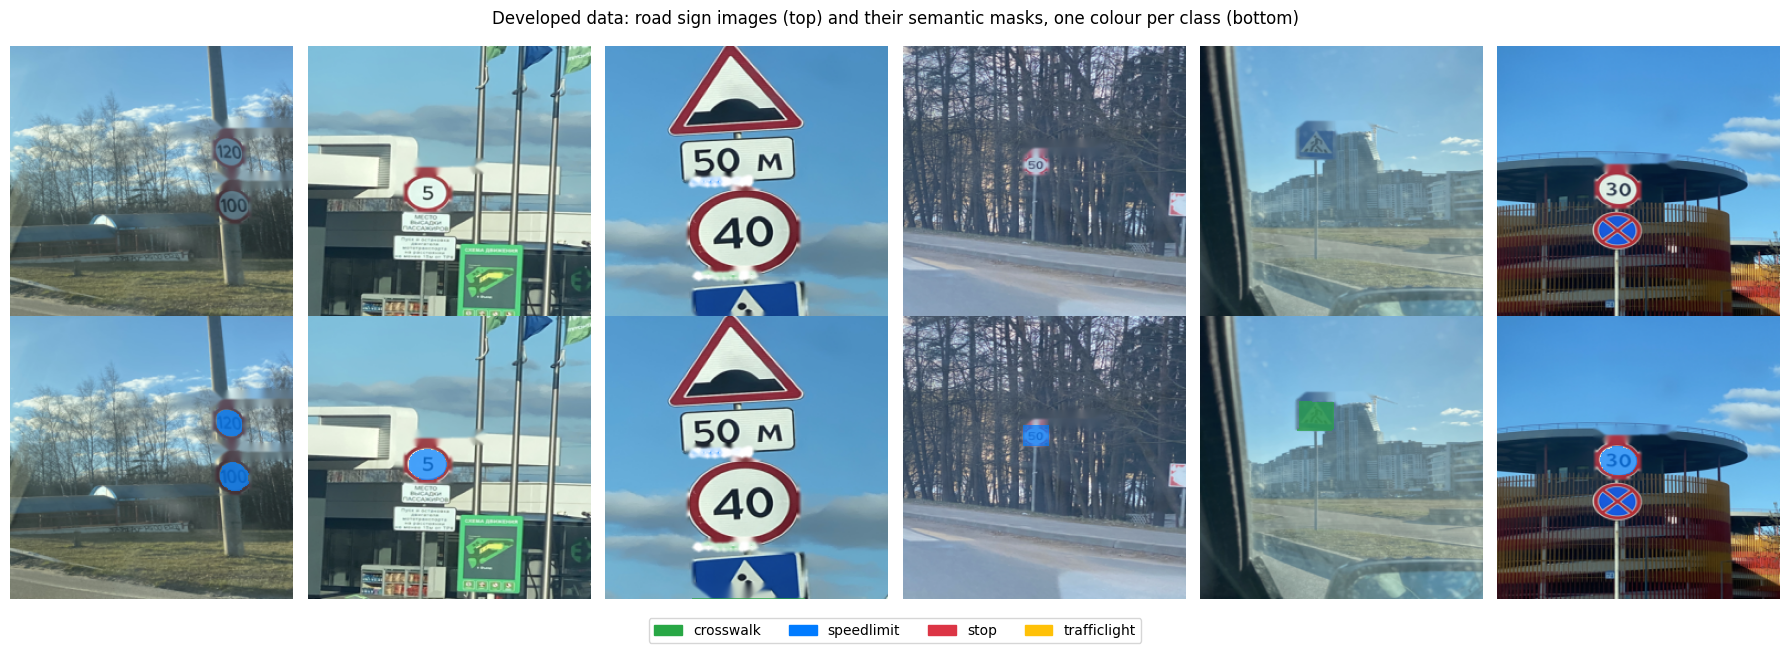

In [11]:
IMG_SIZE = 256  # size used for semantic segmentation (the same as Tutorial 10)


def grabcut_object(img_bgr, box, iterations=5):
    # GrabCut separates the sign from its background inside the labelled box. The area outside the
    # box is used as known background, so the box is cropped with a margin around it.
    H, W = img_bgr.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    bw, bh = x2 - x1, y2 - y1
    full_box = np.zeros((H, W), bool)
    full_box[y1:y2, x1:x2] = True
    if bw < 10 or bh < 10:
        return full_box, 'box'  # too small for GrabCut
    m = max(bw, bh) // 2
    cx1, cy1, cx2, cy2 = max(0, x1 - m), max(0, y1 - m), min(W, x2 + m), min(H, y2 + m)
    crop = np.ascontiguousarray(img_bgr[cy1:cy2, cx1:cx2])
    rx, ry = x1 - cx1, y1 - cy1
    if rx == 0 and ry == 0 and rx + bw == crop.shape[1] and ry + bh == crop.shape[0]:
        return full_box, 'box'  # the box fills the image, so there is no background to learn from
    gc = np.zeros(crop.shape[:2], np.uint8)
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(crop, gc, (rx, ry, bw, bh), bgd, fgd, iterations, cv2.GC_INIT_WITH_RECT)
    except cv2.error:
        return full_box, 'box'
    obj = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
    obj = cv2.morphologyEx(obj, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    obj = cv2.morphologyEx(obj, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    # keep the largest part and fill its holes (e.g. the numbers inside a speed limit sign)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(obj)
    if n > 1:
        obj = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    contours, _ = cv2.findContours(obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    obj = np.zeros_like(obj)
    cv2.drawContours(obj, contours, -1, 1, -1)
    if obj[ry:ry + bh, rx:rx + bw].sum() < 0.25 * bw * bh:
        return full_box, 'box'  # GrabCut lost the sign, keep the whole box
    out = np.zeros((H, W), bool)
    out[cy1:cy2, cx1:cx2] = obj.astype(bool)
    return out & full_box, 'grabcut'


def object_masks(img_path, labels):
    # One mask per labelled sign: from GrabCut inside its box (as in Tutorial 10) or from its polygon
    img = np.array(open_image(img_path))
    H, W = img.shape[:2]
    objects = []
    if label_source == 'polygons':
        for name, pts in labels:
            m = np.zeros((H, W), np.uint8)
            cv2.fillPoly(m, [np.round(pts).astype(np.int32)], 1)
            if m.sum() == 0:
                continue
            ys, xs = np.nonzero(m)
            objects.append((name, [float(xs.min()), float(ys.min()), float(xs.max() + 1), float(ys.max() + 1)],
                            m.astype(bool), 'polygon'))
    else:
        bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        for name, box in labels:
            m, how = grabcut_object(bgr, box)
            if m.sum() == 0:
                continue
            x1, y1, x2, y2 = box
            objects.append((name, [max(0.0, x1), max(0.0, y1), min(float(W), x2), min(float(H), y2)], m, how))
    return img, objects


def class_map(shape, objects):
    # Semantic mask: every pixel gets the class id of its sign (0 = background); small signs are painted last
    cm = np.zeros(shape, np.uint8)
    for name, _, m, _ in sorted(objects, key=lambda o: -o[2].sum()):
        cm[m] = class_to_id[name]
    return cm


def build_set(samples):
    images, objects, xs, ys = [], [], [], []
    for img_path, labels in samples:
        img, objs = object_masks(img_path, labels)
        images.append(img)
        objects.append(objs)
        xs.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
        ys.append(cv2.resize(class_map(img.shape[:2], objs), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST))
    x = torch.tensor(np.stack(xs), dtype=torch.float32).permute(0, 3, 1, 2) / 255
    y = torch.tensor(np.stack(ys), dtype=torch.long)
    return images, objects, x, y


start = time.time()
train_images, train_objects, train_x, train_y = build_set(train_samples)
val_images, val_objects, val_x, val_y = build_set(val_samples)
methods = [o[3] for objs in train_objects + val_objects for o in objs]
print(f'Masks created in {time.time() - start:.1f} s |', ', '.join(f'{k}: {methods.count(k)}' for k in sorted(set(methods))))
print('Semantic segmentation data:', tuple(train_x.shape), tuple(train_y.shape), '|', tuple(val_x.shape))
print('Share of the pixels in the training masks:')
counts = torch.bincount(train_y.flatten(), minlength=num_classes)
for c, name in enumerate(['background'] + class_names):
    print(f'  {name:14} {counts[c] / counts.sum() * 100:6.2f}%')

# Colours for the classes: the colours the boxes were drawn in (black = background)
SIGN_COLORS = np.array([(0, 0, 0)] + [CLASS_COLORS.get(n, tuple(np.random.RandomState(i).randint(60, 255, 3)))
                                      for i, n in enumerate(class_names)], dtype=np.uint8)
SIGN_NAMES = ['background'] + class_names


def show_with_mask(ax, img, cm, title=None):
    ax.imshow(img)
    ax.imshow(np.ma.masked_where(cm == 0, cm), cmap=plt.matplotlib.colors.ListedColormap(SIGN_COLORS / 255),
              vmin=0, vmax=num_classes - 1, alpha=0.7, interpolation='nearest')
    if title:
        ax.set_title(title, fontsize=10)
    ax.axis('off')


fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for k in range(6):
    axes[0, k].imshow(train_x[k].permute(1, 2, 0))
    axes[0, k].axis('off')
    show_with_mask(axes[1, k], train_x[k].permute(1, 2, 0), train_y[k].numpy())
fig.legend(handles=[patches.Patch(color=SIGN_COLORS[c] / 255, label=n) for c, n in enumerate(SIGN_NAMES) if c > 0],
           loc='lower center', ncol=num_classes - 1)
plt.suptitle('Developed data: road sign images (top) and their semantic masks, one colour per class (bottom)')
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Block 9: Task 1 - Test the pretrained DeepLabV3 on the developed data

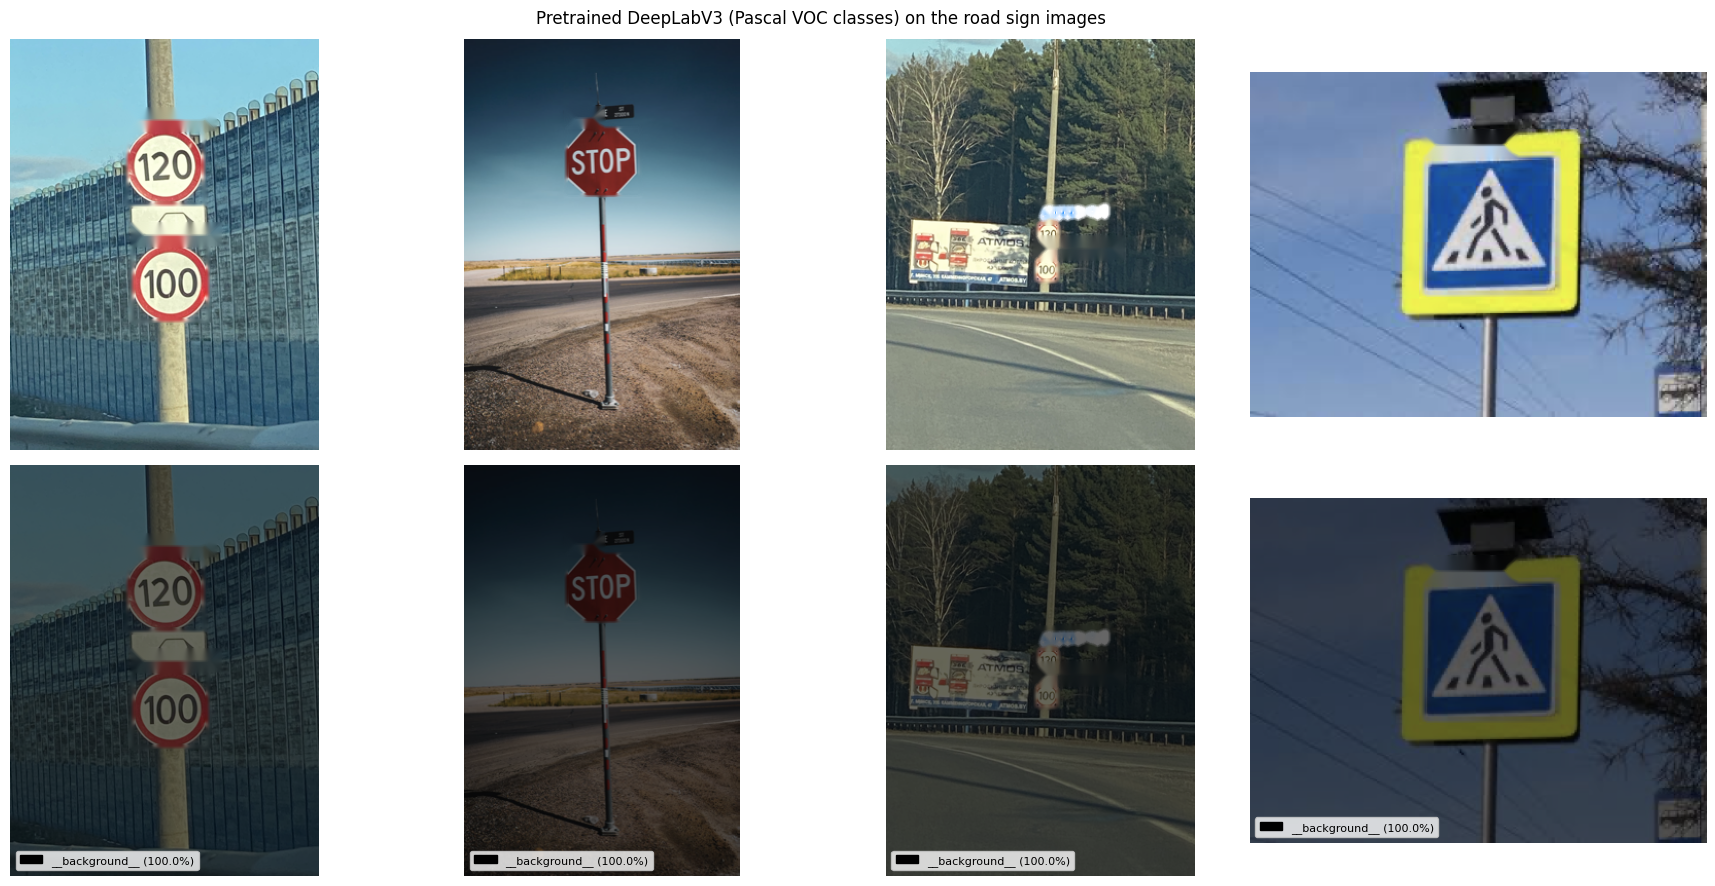

Classes predicted on these images: __background__ 100.0%
There is no road sign class, so the signs are labelled as background or as another class.


In [12]:
# The pretrained model only knows the 21 Pascal VOC classes, which do not include road signs
picks = [i for i in range(len(val_samples)) if val_y[i].sum() > 0][:4]
fig, axes = plt.subplots(2, len(picks), figsize=(4.5 * len(picks), 9))
found = {}
for c, i in enumerate(picks):
    img = Image.fromarray(val_images[i])
    with torch.no_grad():
        pred_voc = model(preprocess(img).unsqueeze(0).to(device))['out'][0].argmax(0).cpu().numpy()
    for v, n in zip(*np.unique(pred_voc, return_counts=True)):
        found[VOC_CLASSES[v]] = found.get(VOC_CLASSES[v], 0) + n
    axes[0, c].imshow(img)
    axes[0, c].axis('off')
    axes[1, c].imshow(img)
    axes[1, c].imshow(decode_segmentation(pred_voc), alpha=0.6)
    axes[1, c].axis('off')
    axes[1, c].legend(handles=class_legend(pred_voc, VOC_CLASSES, VOC_COLORS), loc='lower left', fontsize=8)
plt.suptitle('Pretrained DeepLabV3 (Pascal VOC classes) on the road sign images')
plt.tight_layout()
plt.show()

total = sum(found.values())
print('Classes predicted on these images:', ', '.join(f'{k} {v / total * 100:.1f}%' for k, v in
                                                     sorted(found.items(), key=lambda kv: -kv[1])))
print('There is no road sign class, so the signs are labelled as background or as another class.')

## Block 10: Task 1 - Fine-tune DeepLabV3 on the developed data

In [13]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def normalize(x):
    return (x - MEAN) / STD


def confusion(pred, target, n):
    # rows = true class, columns = predicted class
    return torch.bincount((target * n + pred).flatten(), minlength=n * n).reshape(n, n)


def seg_scores(cm):
    cm = cm.double()
    tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    present = cm.sum(1)[1:] > 0  # sign classes that appear in the ground truth
    sign_tp, sign_fp, sign_fn = cm[1:, 1:].sum(), cm[0, 1:].sum(), cm[1:, 0].sum()
    return {'iou': iou.tolist(), 'miou': iou[1:][present].mean().item(), 'accuracy': (tp.sum() / cm.sum()).item(),
            # all sign classes merged into one "sign" class, the same score as Tutorial 10's U-Net
            'sign_iou': (sign_tp / (sign_tp + sign_fp + sign_fn).clamp(min=1)).item()}


def deeplab_predict(seg_model, x, batch_size=8):
    seg_model.eval()
    preds = []
    with torch.no_grad():
        for k in range(0, len(x), batch_size):
            preds.append(seg_model(normalize(x[k:k + batch_size].to(device)))['out'].argmax(1).cpu())
    return torch.cat(preds)


# DeepLabV3 with a ResNet-50 backbone, pretrained, with a new last layer for background + the sign classes
set_seed(42)
seg_model = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)
seg_model.classifier[4] = nn.Conv2d(256, num_classes, kernel_size=1)
seg_model.aux_classifier = None
seg_model = seg_model.to(device)

# Class weights: the signs cover only a few percent of the pixels (the problem seen in Tutorial 10),
# so mistakes on sign pixels are weighted more in the loss
freq = counts.double() / counts.sum()
class_weights = (1 / freq.clamp(min=1e-6).sqrt())
class_weights = (class_weights / class_weights[0]).clamp(max=20).float().to(device)
print('Class weights:', dict(zip(SIGN_NAMES, class_weights.cpu().numpy().round(1))))

EPOCHS = 30
optimizer = torch.optim.AdamW([{'params': seg_model.backbone.parameters(), 'lr': 1e-4},
                               {'params': seg_model.classifier.parameters(), 'lr': 1e-3}], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
seg_history = {'loss': [], 'val_miou': [], 'val_sign_iou': []}
start = time.time()
for epoch in range(EPOCHS):
    seg_model.train()
    order = torch.randperm(len(train_x))
    total, steps = 0.0, 0
    for k in range(0, len(order), 8):
        idx = order[k:k + 8]
        if len(idx) < 2:
            continue  # batch normalization needs at least 2 images
        xb, yb = train_x[idx].to(device), train_y[idx].to(device)
        flip = torch.rand(len(idx), device=device) < 0.5
        xb[flip] = xb[flip].flip(-1)
        yb[flip] = yb[flip].flip(-1)
        loss = F.cross_entropy(seg_model(normalize(xb))['out'], yb, weight=class_weights)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
        steps += 1
    scheduler.step()
    s = seg_scores(confusion(deeplab_predict(seg_model, val_x), val_y, num_classes))
    seg_history['loss'].append(total / steps)
    seg_history['val_miou'].append(s['miou'])
    seg_history['val_sign_iou'].append(s['sign_iou'])
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {total / steps:.4f} - val_mIoU: {s['miou']:.4f} - val_sign_IoU: {s['sign_iou']:.4f}")
deeplab_time = time.time() - start
print(f'Training time: {deeplab_time:.1f} s')

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 177MB/s]


Class weights: {'background': np.float32(1.0), 'crosswalk': np.float32(10.6), 'speedlimit': np.float32(8.6), 'stop': np.float32(12.1), 'trafficlight': np.float32(18.9)}
Epoch 1/30 - loss: 1.0510 - val_mIoU: 0.1340 - val_sign_IoU: 0.0906
Epoch 5/30 - loss: 0.1140 - val_mIoU: 0.4430 - val_sign_IoU: 0.5378
Epoch 10/30 - loss: 0.0469 - val_mIoU: 0.6197 - val_sign_IoU: 0.6774
Epoch 15/30 - loss: 0.0314 - val_mIoU: 0.6124 - val_sign_IoU: 0.6888
Epoch 20/30 - loss: 0.0239 - val_mIoU: 0.6252 - val_sign_IoU: 0.6873
Epoch 25/30 - loss: 0.0229 - val_mIoU: 0.6275 - val_sign_IoU: 0.6941
Epoch 30/30 - loss: 0.0220 - val_mIoU: 0.6281 - val_sign_IoU: 0.6967
Training time: 801.1 s


## Block 11: Task 1 - Evaluate and visualize DeepLabV3

Class              IoU
background       0.990
crosswalk        0.728
speedlimit       0.694
stop             0.823
trafficlight     0.268
mIoU (sign classes): 0.628 | sign IoU (all signs as one class): 0.697 | pixel accuracy: 0.9905


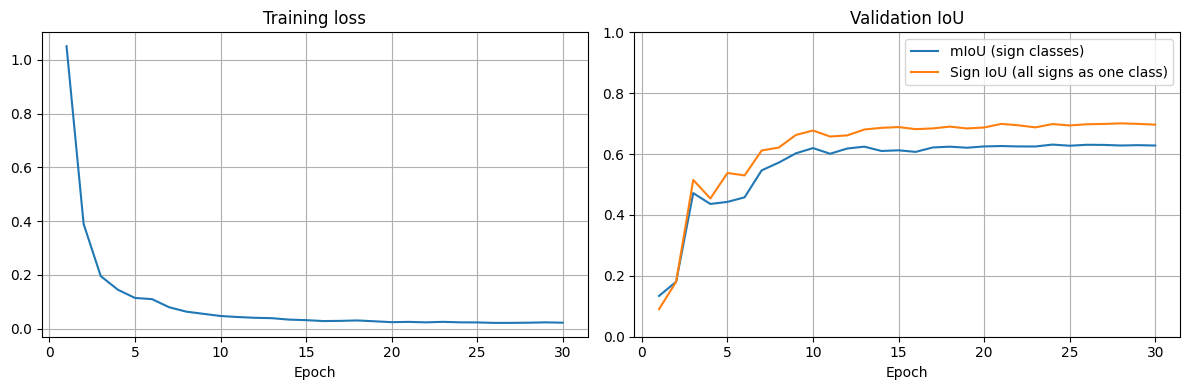

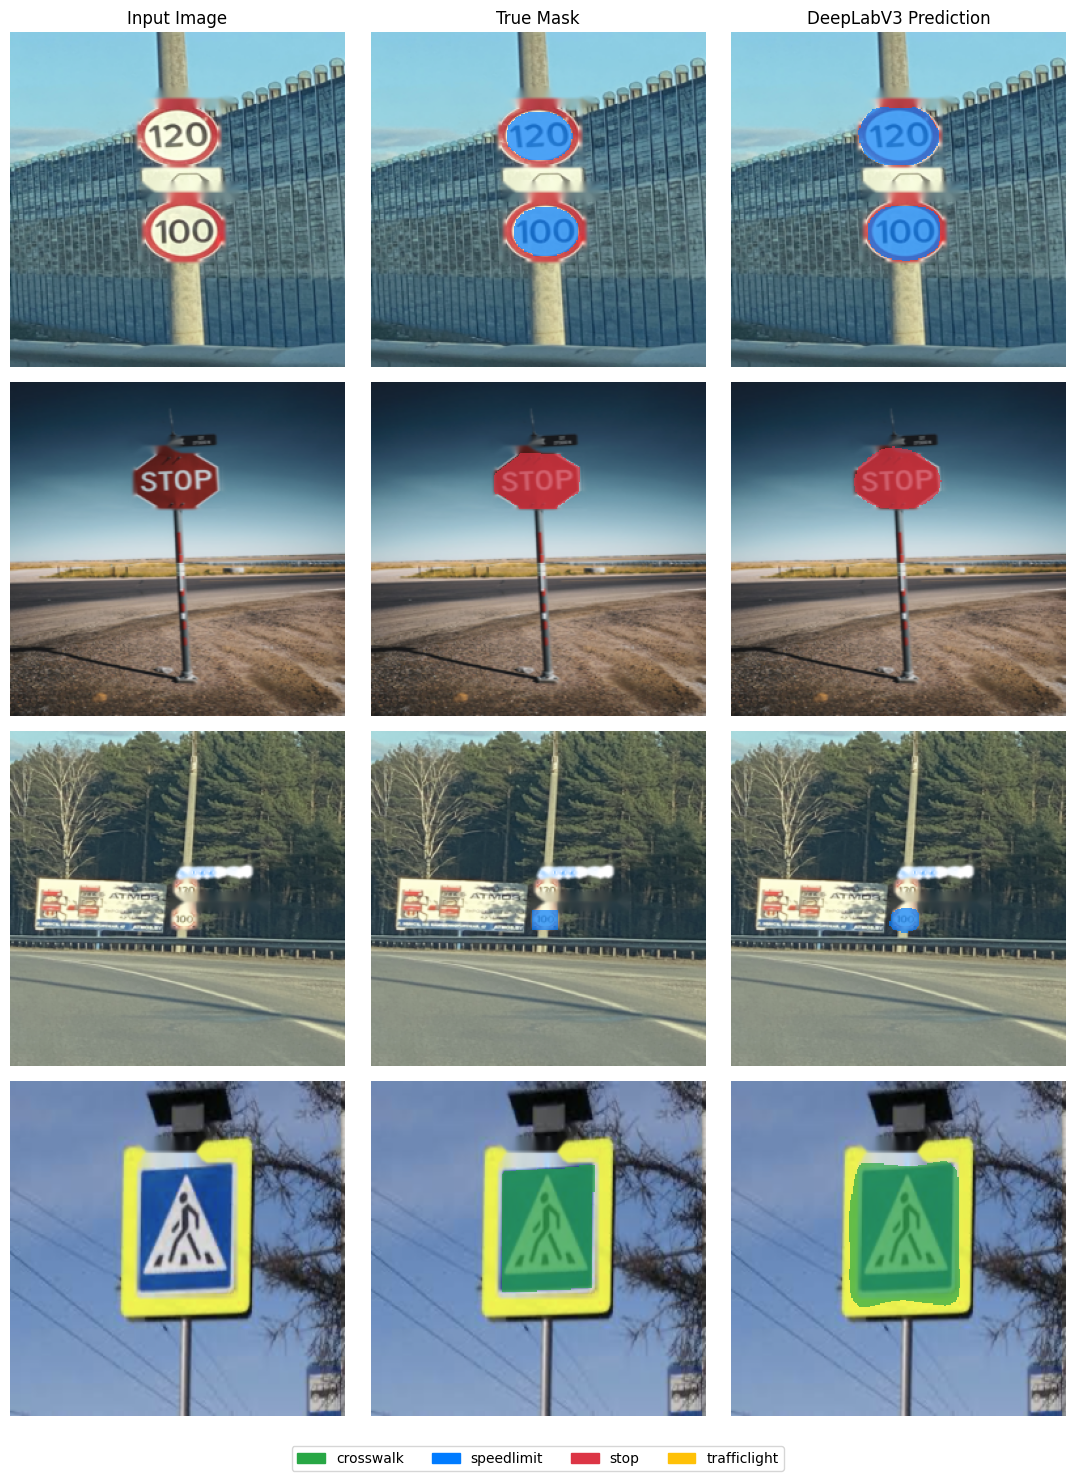

In [14]:
deeplab_pred = deeplab_predict(seg_model, val_x)
deeplab_scores = seg_scores(confusion(deeplab_pred, val_y, num_classes))

print(f"{'Class':14} {'IoU':>7}")
for name, iou in zip(SIGN_NAMES, deeplab_scores['iou']):
    print(f"{name:14} {iou:7.3f}")
print(f"mIoU (sign classes): {deeplab_scores['miou']:.3f} | sign IoU (all signs as one class): "
      f"{deeplab_scores['sign_iou']:.3f} | pixel accuracy: {deeplab_scores['accuracy']:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), seg_history['loss'])
plt.title('Training loss')
plt.xlabel('Epoch')
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), seg_history['val_miou'], label='mIoU (sign classes)')
plt.plot(range(1, EPOCHS + 1), seg_history['val_sign_iou'], label='Sign IoU (all signs as one class)')
plt.title('Validation IoU')
plt.xlabel('Epoch')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

picks = [i for i in range(len(val_x)) if val_y[i].sum() > 0][:4]
fig, axes = plt.subplots(len(picks), 3, figsize=(11, 3.7 * len(picks)))
for r, i in enumerate(picks):
    axes[r, 0].imshow(val_x[i].permute(1, 2, 0))
    axes[r, 0].axis('off')
    show_with_mask(axes[r, 1], val_x[i].permute(1, 2, 0), val_y[i].numpy())
    show_with_mask(axes[r, 2], val_x[i].permute(1, 2, 0), deeplab_pred[i].numpy())
    if r == 0:
        axes[r, 0].set_title('Input Image')
        axes[r, 1].set_title('True Mask')
        axes[r, 2].set_title('DeepLabV3 Prediction')
fig.legend(handles=[patches.Patch(color=SIGN_COLORS[c] / 255, label=n) for c, n in enumerate(SIGN_NAMES) if c > 0],
           loc='lower center', ncol=num_classes - 1)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Block 12: Task 2 - Mask R-CNN: pretrained model on the random image

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 120MB/s]


29 objects found (score >= 0.5):
  car            1.00
  car            1.00
  person         1.00
  motorcycle     0.99
  car            0.99
  person         0.98
  traffic light  0.98
  car            0.98
  car            0.97
  fire hydrant   0.96
  person         0.96
  car            0.96
  car            0.95
  car            0.93
  car            0.93
  car            0.93
  car            0.93
  car            0.90
  car            0.89
  car            0.87
  car            0.86
  car            0.83
  car            0.81
  car            0.81
  car            0.74
  car            0.74
  car            0.65
  car            0.59
  car            0.55


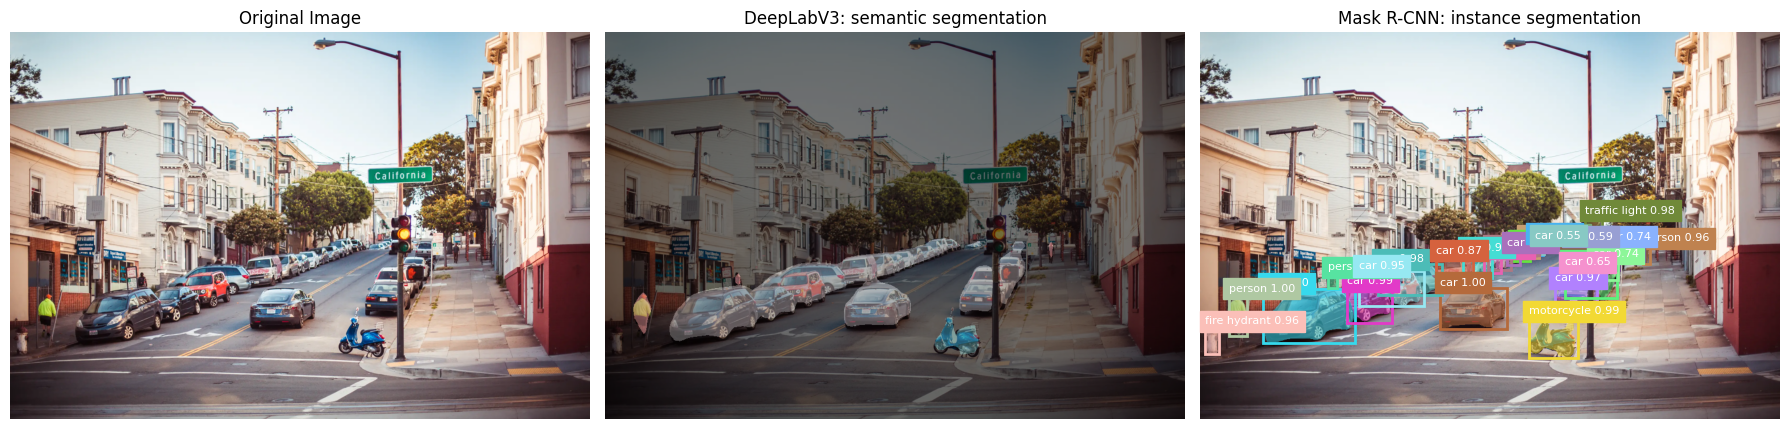

In [15]:
mr_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
maskrcnn = maskrcnn_resnet50_fpn(weights=mr_weights).to(device).eval()
COCO_CLASSES = mr_weights.meta['categories']

with torch.no_grad():
    out = maskrcnn([TF.to_tensor(image).to(device)])[0]
keep = (out['scores'] >= 0.5).nonzero().flatten().tolist()
print(f'{len(keep)} objects found (score >= 0.5):')
for k in keep:
    print(f"  {COCO_CLASSES[out['labels'][k]]:14} {out['scores'][k]:.2f}")

# Every object (instance) gets its own colour, even if two objects are of the same class
rng = np.random.default_rng(0)
overlay = np.array(image).astype(np.float32) / 255
plt.figure(figsize=(18, 6))
ax = plt.subplot(1, 3, 3)
for k in keep:
    color = rng.uniform(0.2, 1.0, 3)
    m = (out['masks'][k, 0] > 0.5).cpu().numpy()
    overlay[m] = 0.45 * overlay[m] + 0.55 * color
    x1, y1, x2, y2 = out['boxes'][k].tolist()
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
    ax.text(x1, y1 - 4, f"{COCO_CLASSES[out['labels'][k]]} {out['scores'][k]:.2f}", color='white', fontsize=8,
            backgroundcolor=tuple(color))
ax.imshow(overlay)
ax.set_title('Mask R-CNN: instance segmentation')
ax.axis('off')

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(image)
plt.imshow(segmentation_map, alpha=0.55)
plt.title('DeepLabV3: semantic segmentation')
plt.axis('off')
plt.tight_layout()
plt.show()

## Block 13: Task 2 - Train Mask R-CNN on the developed data

In [16]:
class InstanceDataset(Dataset):
    def __init__(self, images, objects, train=False):
        self.images, self.objects, self.train = images, objects, train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        H, W = img.shape[:2]
        objs = [o for o in self.objects[i] if o[1][2] - o[1][0] >= 1 and o[1][3] - o[1][1] >= 1]
        image = TF.to_tensor(img)
        boxes = torch.tensor([o[1] for o in objs], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([class_to_id[o[0]] for o in objs], dtype=torch.int64)
        if objs:
            masks = torch.from_numpy(np.stack([o[2] for o in objs]).astype(np.uint8))
        else:
            masks = torch.zeros((0, H, W), dtype=torch.uint8)
        if self.train and random.random() < 0.5:  # random horizontal flip
            image, masks = image.flip(-1), masks.flip(-1)
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        return image, {'boxes': boxes, 'labels': labels, 'masks': masks}


def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(InstanceDataset(train_images, train_objects, train=True), batch_size=4, shuffle=True,
                          num_workers=2, collate_fn=collate_fn)

# Mask R-CNN pretrained on COCO, with new box and mask predictors for background + the sign classes
set_seed(42)
mask_model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT)
in_features = mask_model.roi_heads.box_predictor.cls_score.in_features
mask_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
in_features_mask = mask_model.roi_heads.mask_predictor.conv5_mask.in_channels
mask_model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, 256, num_classes)
mask_model = mask_model.to(device)

MR_EPOCHS = 15
params = [p for p in mask_model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
mr_history = {'loss': [], 'loss_mask': []}
start = time.time()
for epoch in range(MR_EPOCHS):
    mask_model.train()
    total, total_mask = 0.0, 0.0
    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = mask_model(images, targets)  # box, class, mask and RPN losses
        loss = sum(loss_dict.values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
        total_mask += loss_dict['loss_mask'].item()
    scheduler.step()
    mr_history['loss'].append(total / len(train_loader))
    mr_history['loss_mask'].append(total_mask / len(train_loader))
    print(f"Epoch {epoch + 1}/{MR_EPOCHS} - loss: {mr_history['loss'][-1]:.4f} - mask loss: {mr_history['loss_mask'][-1]:.4f}")
maskrcnn_time = time.time() - start
print(f'Training time: {maskrcnn_time:.1f} s')

Epoch 1/15 - loss: 0.9595 - mask loss: 0.4549
Epoch 2/15 - loss: 0.5066 - mask loss: 0.2865
Epoch 3/15 - loss: 0.3858 - mask loss: 0.2278
Epoch 4/15 - loss: 0.3498 - mask loss: 0.1910
Epoch 5/15 - loss: 0.2986 - mask loss: 0.1712
Epoch 6/15 - loss: 0.2732 - mask loss: 0.1604
Epoch 7/15 - loss: 0.2469 - mask loss: 0.1480
Epoch 8/15 - loss: 0.2156 - mask loss: 0.1267
Epoch 9/15 - loss: 0.2037 - mask loss: 0.1119
Epoch 10/15 - loss: 0.1728 - mask loss: 0.0973
Epoch 11/15 - loss: 0.1708 - mask loss: 0.0974
Epoch 12/15 - loss: 0.1500 - mask loss: 0.0871
Epoch 13/15 - loss: 0.1482 - mask loss: 0.0892
Epoch 14/15 - loss: 0.1466 - mask loss: 0.0875
Epoch 15/15 - loss: 0.1428 - mask loss: 0.0867
Training time: 559.7 s


## Block 14: Task 2 - Evaluate and visualize Mask R-CNN

Class           Mask IoU  Box AP@0.5  Box AP@0.75
background         0.994           -            -
crosswalk          0.781       0.784        0.750
speedlimit         0.804       0.919        0.919
stop               0.841       0.750        0.750
trafficlight       0.587       0.587        0.167
Mask mIoU (sign classes): 0.753 | sign IoU: 0.796 | box mAP@0.5: 0.760 | box mAP@0.75: 0.647


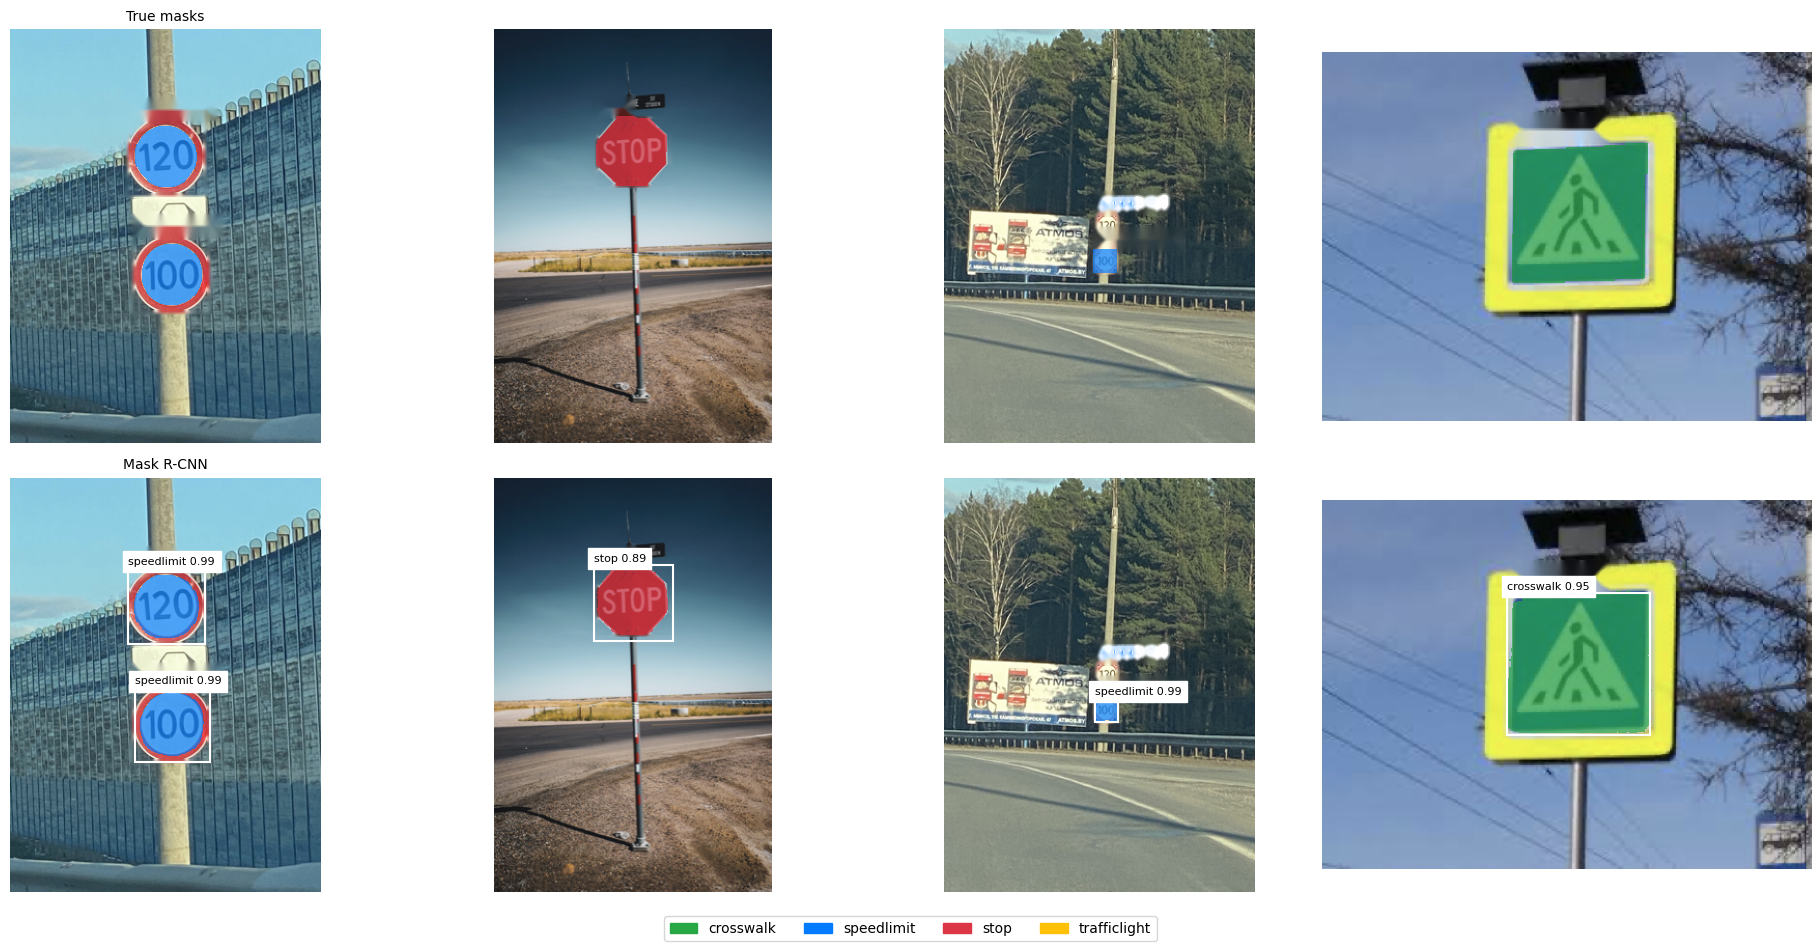

In [17]:
def calculate_iou(box1, box2):
    xmin1, ymin1, xmax1, ymax1 = box1
    xmin2, ymin2, xmax2, ymax2 = box2
    inter_area = max(0, min(xmax1, xmax2) - max(xmin1, xmin2)) * max(0, min(ymax1, ymax2) - max(ymin1, ymin2))
    area1 = (xmax1 - xmin1) * (ymax1 - ymin1)
    area2 = (xmax2 - xmin2) * (ymax2 - ymin2)
    union_area = area1 + area2 - inter_area
    return inter_area / union_area if union_area != 0 else 0


def calculate_ap(precisions, recalls):
    precisions = [0.0] + precisions + [0.0]
    recalls = [0.0] + recalls + [1.0]
    for i in range(len(precisions) - 1, 0, -1):
        precisions[i - 1] = max(precisions[i - 1], precisions[i])
    indices = [i for i in range(1, len(recalls)) if recalls[i] != recalls[i - 1]]
    return sum((recalls[i] - recalls[i - 1]) * precisions[i] for i in indices)


def evaluate_class(predictions, ground_truths, class_id, iou_threshold=0.5, score_threshold=0.5):
    # Ranks every detection of one class by score and uses calculate_iou and calculate_ap from above
    detections, gt_by_image, n_gt = [], {}, 0
    for i, (pred, gt) in enumerate(zip(predictions, ground_truths)):
        gt_by_image[i] = [box for box, l in zip(gt['boxes'], gt['labels']) if l == class_id]
        n_gt += len(gt_by_image[i])
        detections += [(s, i, box) for box, s, l in zip(pred['boxes'], pred['scores'], pred['labels']) if l == class_id]
    if n_gt == 0:
        return None

    detections.sort(key=lambda d: -d[0])
    matched = {i: set() for i in gt_by_image}
    tp = fp = 0
    precisions, recalls = [], []
    precision_at, recall_at = 0.0, 0.0
    for score, i, box in detections:
        best_iou, best_j = 0, -1
        for j, gt_box in enumerate(gt_by_image[i]):
            if j not in matched[i]:
                iou = calculate_iou(box, gt_box)
                if iou > best_iou:
                    best_iou, best_j = iou, j
        if best_iou >= iou_threshold:
            tp += 1
            matched[i].add(best_j)
        else:
            fp += 1
        precisions.append(tp / (tp + fp))
        recalls.append(tp / n_gt)
        if score >= score_threshold:
            precision_at, recall_at = precisions[-1], recalls[-1]

    return calculate_ap(precisions, recalls), precision_at, recall_at, n_gt


mask_model.eval()
mr_predictions = []
with torch.no_grad():
    for img in val_images:
        out = mask_model([TF.to_tensor(img).to(device)])[0]
        mr_predictions.append({k: v.cpu() for k, v in out.items()})


def instances_to_class_map(out, shape, score_threshold=0.5):
    # Paint the predicted masks into one semantic mask (highest scores on top), to compare with DeepLabV3
    cm = np.zeros(shape, np.uint8)
    for k in out['scores'].argsort().tolist():
        if out['scores'][k] >= score_threshold:
            cm[(out['masks'][k, 0] > 0.5).numpy()] = int(out['labels'][k])
    return cm


# a) Masks: same 256x256 ground truth and IoU as DeepLabV3
mr_class_maps = torch.tensor(np.stack([cv2.resize(instances_to_class_map(out, img.shape[:2]), (IMG_SIZE, IMG_SIZE),
                                                  interpolation=cv2.INTER_NEAREST)
                                       for out, img in zip(mr_predictions, val_images)]), dtype=torch.long)
maskrcnn_scores = seg_scores(confusion(mr_class_maps, val_y, num_classes))

# b) Boxes: AP with the same functions as Tutorials 8 and 9
box_preds = [{'boxes': o['boxes'].tolist(), 'scores': o['scores'].tolist(), 'labels': o['labels'].tolist()}
             for o in mr_predictions]
box_gts = [{'boxes': [o[1] for o in objs], 'labels': [class_to_id[o[0]] for o in objs]} for objs in val_objects]

print(f"{'Class':14} {'Mask IoU':>9} {'Box AP@0.5':>11} {'Box AP@0.75':>12}")
box_ap50, box_ap75 = [], []
for c, name in enumerate(SIGN_NAMES):
    r50 = evaluate_class(box_preds, box_gts, c, iou_threshold=0.5) if c > 0 else None
    r75 = evaluate_class(box_preds, box_gts, c, iou_threshold=0.75) if c > 0 else None
    if r50 is not None:
        box_ap50.append(r50[0])
        box_ap75.append(r75[0])
    ap50 = f'{r50[0]:11.3f}' if r50 is not None else f"{'-':>11}"
    ap75 = f'{r75[0]:12.3f}' if r75 is not None else f"{'-':>12}"
    print(f"{name:14} {maskrcnn_scores['iou'][c]:9.3f} {ap50} {ap75}")
maskrcnn_box_map50, maskrcnn_box_map75 = float(np.mean(box_ap50)), float(np.mean(box_ap75))
print(f"Mask mIoU (sign classes): {maskrcnn_scores['miou']:.3f} | sign IoU: {maskrcnn_scores['sign_iou']:.3f}"
      f" | box mAP@0.5: {maskrcnn_box_map50:.3f} | box mAP@0.75: {maskrcnn_box_map75:.3f}")

picks = [i for i in range(len(val_images)) if val_y[i].sum() > 0][:4]
fig, axes = plt.subplots(2, len(picks), figsize=(4.8 * len(picks), 9.5))
for c, i in enumerate(picks):
    img, out = val_images[i], mr_predictions[i]
    show_with_mask(axes[0, c], img, class_map(img.shape[:2], val_objects[i]), 'True masks' if c == 0 else None)
    show_with_mask(axes[1, c], img, instances_to_class_map(out, img.shape[:2]), 'Mask R-CNN' if c == 0 else None)
    for k in range(len(out['scores'])):
        if out['scores'][k] >= 0.5:
            x1, y1, x2, y2 = out['boxes'][k].tolist()
            axes[1, c].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='white', linewidth=1.5))
            axes[1, c].text(x1, y1 - 3, f"{SIGN_NAMES[out['labels'][k]]} {out['scores'][k]:.2f}", color='black',
                            fontsize=8, backgroundcolor='white')
fig.legend(handles=[patches.Patch(color=SIGN_COLORS[c] / 255, label=n) for c, n in enumerate(SIGN_NAMES) if c > 0],
           loc='lower center', ncol=num_classes - 1)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Block 15: Summary

Model                           Sign IoU  mIoU (classes)  Train time (s)
U-Net from scratch (Tut. 10)       0.418               -               -
DeepLabV3 ResNet-50                0.697           0.628           801.1
Mask R-CNN ResNet-50 FPN           0.796           0.753           559.7
Mask R-CNN boxes: mAP@0.5 = 0.760, mAP@0.75 = 0.647


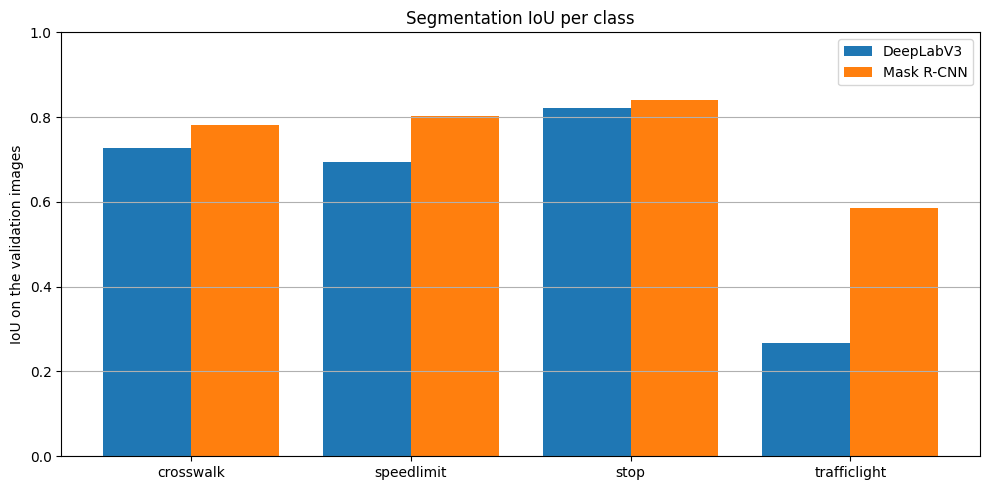

In [18]:
TUTORIAL10_UNET_SIGN_IOU = 0.418  # best U-Net in Tutorial 10 (Deeper + BatchNorm + Dropout), same masks and images

print(f"{'Model':30} {'Sign IoU':>9} {'mIoU (classes)':>15} {'Train time (s)':>15}")
print(f"{'U-Net from scratch (Tut. 10)':30} {TUTORIAL10_UNET_SIGN_IOU:9.3f} {'-':>15} {'-':>15}")
print(f"{'DeepLabV3 ResNet-50':30} {deeplab_scores['sign_iou']:9.3f} {deeplab_scores['miou']:15.3f} {deeplab_time:15.1f}")
print(f"{'Mask R-CNN ResNet-50 FPN':30} {maskrcnn_scores['sign_iou']:9.3f} {maskrcnn_scores['miou']:15.3f} {maskrcnn_time:15.1f}")
print(f"Mask R-CNN boxes: mAP@0.5 = {maskrcnn_box_map50:.3f}, mAP@0.75 = {maskrcnn_box_map75:.3f}")

x = np.arange(len(class_names))
plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, deeplab_scores['iou'][1:], width=0.4, label='DeepLabV3')
plt.bar(x + 0.2, maskrcnn_scores['iou'][1:], width=0.4, label='Mask R-CNN')
plt.xticks(x, class_names)
plt.ylim(0, 1)
plt.ylabel('IoU on the validation images')
plt.title('Segmentation IoU per class')
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()